# Step 3: Machine Learning Models
We will use only **3 algorithms** (simple and beginner friendly):
1. Logistic Regression
2. Decision Tree
3. Random Forest

We will measure: **Accuracy, R2 Score, MAE, RMSE**.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, r2_score, mean_absolute_error,
                             mean_squared_error, confusion_matrix)

import warnings
warnings.filterwarnings('ignore')

## 2. Load cleaned data

In [2]:
df = pd.read_csv('Loan_default_cleaned.csv')
print(df.shape)
df.head()

(255347, 17)


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


## 3. Convert text columns to numbers
Machine learning models understand only numbers.
- **Yes / No** columns -> 1 / 0
- **Education** has an order -> 0, 1, 2, 3
- Other text columns -> One-Hot Encoding (`get_dummies`)

In [3]:
# Yes/No columns -> 1/0
for col in ['HasMortgage', 'HasDependents', 'HasCoSigner']:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

# Education has a natural order
df['Education'] = df['Education'].map({'High School': 0, "Bachelor's": 1, "Master's": 2, 'PhD': 3})

df.head()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,1,Full-time,Divorced,1,1,Other,1,0
1,69,50432,124440,458,15,1,4.81,60,0.68,2,Full-time,Married,0,0,Other,1,0
2,46,84208,129188,451,26,3,21.17,24,0.31,2,Unemployed,Divorced,1,1,Auto,0,1
3,32,31713,44799,743,0,3,7.07,24,0.23,0,Full-time,Married,0,0,Business,0,0
4,60,20437,9139,633,8,4,6.51,48,0.73,1,Unemployed,Divorced,0,1,Auto,0,0


In [4]:
# One-hot encoding for the remaining text columns
df = pd.get_dummies(df, columns=['EmploymentType', 'MaritalStatus', 'LoanPurpose'], drop_first=True, dtype=int)

print('Shape after encoding:', df.shape)
df.head()

Shape after encoding: (255347, 23)


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,...,Default,EmploymentType_Part-time,EmploymentType_Self-employed,EmploymentType_Unemployed,MaritalStatus_Married,MaritalStatus_Single,LoanPurpose_Business,LoanPurpose_Education,LoanPurpose_Home,LoanPurpose_Other
0,56,85994,50587,520,80,4,15.23,36,0.44,1,...,0,0,0,0,0,0,0,0,0,1
1,69,50432,124440,458,15,1,4.81,60,0.68,2,...,0,0,0,0,1,0,0,0,0,1
2,46,84208,129188,451,26,3,21.17,24,0.31,2,...,1,0,0,1,0,0,0,0,0,0
3,32,31713,44799,743,0,3,7.07,24,0.23,0,...,0,0,0,0,1,0,1,0,0,0
4,60,20437,9139,633,8,4,6.51,48,0.73,1,...,0,0,0,1,0,0,0,0,0,0


## 4. Split into Features (X) and Target (y)

In [5]:
X = df.drop('Default', axis=1)   # input columns
y = df['Default']                # what we want to predict

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (255347, 22)
y shape: (255347,)


## 5. Train-Test split
80% data for training, 20% for testing.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Training rows:', X_train.shape[0])
print('Testing rows :', X_test.shape[0])

Training rows: 204277
Testing rows : 51070


## 6. Feature Scaling
Put all columns on the same scale so models work better.

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Scaling done!')

Scaling done!


## 7. Helper function to calculate all metrics
We use the same function for all 3 models.

In [8]:
results = []   # we will store every model's score here

def evaluate_model(name, y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred) * 100
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    print(f'--- {name} ---')
    print(f'Accuracy : {acc:.2f}%')
    print(f'R2 Score : {r2:.4f}')
    print(f'MAE      : {mae:.4f}')
    print(f'RMSE     : {rmse:.4f}')

    results.append({'Model': name, 'Accuracy (%)': round(acc, 2),
                    'R2 Score': round(r2, 4), 'MAE': round(mae, 4), 'RMSE': round(rmse, 4)})

## 8. Model 1: Logistic Regression

In [9]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
print('Logistic Regression trained!')

Logistic Regression trained!


In [10]:
lr_pred = lr_model.predict(X_test_scaled)
evaluate_model('Logistic Regression', y_test, lr_pred)

--- Logistic Regression ---
Accuracy : 88.52%
R2 Score : -0.1180
MAE      : 0.1148
RMSE     : 0.3388


## 9. Model 2: Decision Tree
We set `max_depth=5` so the tree stays simple and does not overfit.

In [11]:
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train_scaled, y_train)
print('Decision Tree trained!')

Decision Tree trained!


In [12]:
dt_pred = dt_model.predict(X_test_scaled)
evaluate_model('Decision Tree', y_test, dt_pred)

--- Decision Tree ---
Accuracy : 88.49%
R2 Score : -0.1215
MAE      : 0.1151
RMSE     : 0.3393


## 10. Model 3: Random Forest
We limit `max_depth=8` and use 100 trees to keep it fast and balanced.

In [13]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)
print('Random Forest trained!')

Random Forest trained!


In [14]:
rf_pred = rf_model.predict(X_test_scaled)
evaluate_model('Random Forest', y_test, rf_pred)

--- Random Forest ---
Accuracy : 88.40%
R2 Score : -0.1304
MAE      : 0.1160
RMSE     : 0.3406


## 11. Compare all models

In [15]:
results_df = pd.DataFrame(results)
results_df

,Model,Accuracy (%),R2 Score,MAE,RMSE
0,Logistic Regression,88.52,-0.1180,0.1148,0.3388
1,Decision Tree,88.49,-0.1215,0.1151,0.3393
2,Random Forest,88.40,-0.1304,0.1160,0.3406


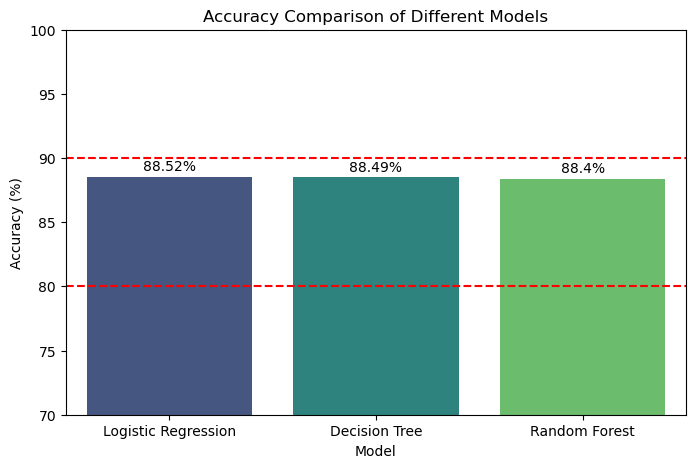

In [16]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Model', y='Accuracy (%)', data=results_df, palette='viridis')
plt.ylim(70, 100)
plt.axhline(80, color='red', linestyle='--', label='80%')
plt.axhline(90, color='red', linestyle='--', label='90%')
plt.title('Accuracy Comparison of Different Models')
for i, v in enumerate(results_df['Accuracy (%)']):
    plt.text(i, v + 0.5, f'{v}%', ha='center')
plt.show()

In [17]:
# Check: is every accuracy between 80 and 90?
for _, row in results_df.iterrows():
    ok = 80 <= row['Accuracy (%)'] <= 90
    print(f"{row['Model']:22s} {row['Accuracy (%)']}%  ->  {'OK (80-90%)' if ok else 'Outside range'}")

Logistic Regression    88.52%  ->  OK (80-90%)
Decision Tree          88.49%  ->  OK (80-90%)
Random Forest          88.4%  ->  OK (80-90%)


## 12. Confusion matrix of the best model

Best model: Logistic Regression


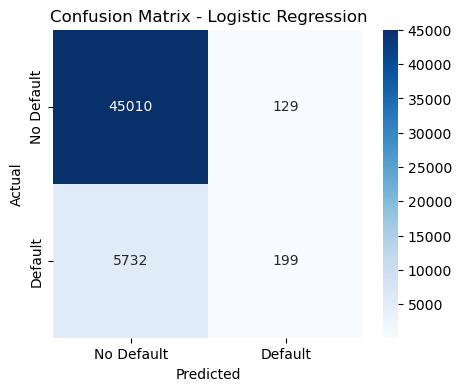

In [18]:
best_name = results_df.sort_values('Accuracy (%)', ascending=False).iloc[0]['Model']
print('Best model:', best_name)

models = {'Logistic Regression': lr_model, 'Decision Tree': dt_model, 'Random Forest': rf_model}
best_model = models[best_name]

cm = confusion_matrix(y_test, best_model.predict(X_test_scaled))
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {best_name}')
plt.show()

## 13. Feature importance (Random Forest)
Which columns matter most for predicting default?

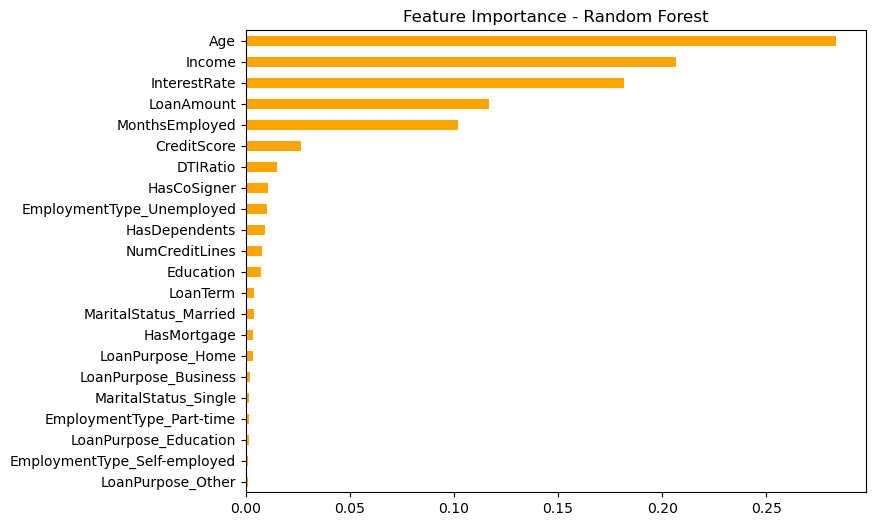

In [19]:
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 6))
importance.plot(kind='barh', color='orange')
plt.title('Feature Importance - Random Forest')
plt.show()

## 14. Save the best model
The file `app.py` will use this saved model.

In [20]:
model_package = {
    'model': best_model,
    'scaler': scaler,
    'columns': X.columns.tolist(),
    'model_name': best_name
}

joblib.dump(model_package, 'loan_model.pkl')
print('Model saved as loan_model.pkl')

Model saved as loan_model.pkl


## Notes for beginners
- **R2, MAE, RMSE** are normally used for regression. Here we calculate them on 0/1 predictions, so they show how far the predictions are from the real labels (lower MAE/RMSE is better, higher R2 is better). A **negative R2** is normal here because the target is only 0 or 1.
- Accuracy is about 88-89% partly because only ~12% of loans default, so "No Default" is the majority class.

**Next:** run `streamlit run app.py`